# 2. Visualising NCA Attractors -- Blue/Green Gecko (Microscopic)
## Pixel level / dense autoencoder
### James Stovold
### April 2026


Code to support ALIFE 2026 paper:
 > Stovold, Kvalsund, Ludwig, Sharma, Mordvintsev "Visualising the Attractor Landscape of Neural Cellular Automata"

Based on the Colab notebook developed by Mordvintsev et al. for the ["Growing Neural Cellular Automata"](http://distill.pub/2020/growing-ca) article. and J. Stovold's notebook for the ["Neural Cellular Automata can Respond to Signals"](https://github.com/jstovold/ALIFE2023/blob/master/ExternalSignals.ipynb) article at ALIFE 2023.

Code and materials are restricted for any and all use prior to publication; post-publication the code and associated materials are available under the Apache 2.0 license


In [4]:
import tensorflow as tf
gpus = tf.config.list_physical_devices('GPU')
if gpus:
  try:
    # Currently, memory growth needs to be the same across GPUs
    for gpu in gpus:
      tf.config.experimental.set_memory_growth(gpu, True)
    logical_gpus = tf.config.list_logical_devices('GPU')
    print(len(gpus), "Physical GPUs,", len(logical_gpus), "Logical GPUs")
  except RuntimeError as e:
    # Memory growth must be set before GPUs have been initialized
    print(e)


1 Physical GPUs, 1 Logical GPUs


In [5]:
root_dir = './jamess/ALICE_Paper/4_bluegreen_pixel/'
!mkdir -p {root_dir}


In [1]:

#@title Imports and Notebook Utilities


import os
import io
import PIL.Image, PIL.ImageDraw
import base64
import zipfile
import json
import requests
import numpy as np
import matplotlib.pylab as pl
import glob
import random
import datetime

from scipy.ndimage.interpolation import rotate as scipy_rotate


import tensorflow as tf

from IPython.display import Image, HTML, clear_output
import tqdm

import os
os.environ['FFMPEG_BINARY'] = 'ffmpeg'
import moviepy as mvp
from moviepy.video.io.ffmpeg_writer import FFMPEG_VideoWriter
clear_output()

def np2pil(a):
  if a.dtype in [np.float32, np.float64]:
    a = np.uint8(np.clip(a, 0, 1)*255)
  return PIL.Image.fromarray(a)

def imwrite(f, a, fmt=None):
  a = np.asarray(a)
  if isinstance(f, str):
    fmt = f.rsplit('.', 1)[-1].lower()
    if fmt == 'jpg':
      fmt = 'jpeg'
    f = open(f, 'wb')
  np2pil(a).save(f, fmt, quality=95)

def imencode(a, fmt='jpeg'):
  a = np.asarray(a)
  if len(a.shape) == 3 and a.shape[-1] == 4:
    fmt = 'png'
  f = io.BytesIO()
  imwrite(f, a, fmt)
  return f.getvalue()

def im2url(a, fmt='jpeg'):
  encoded = imencode(a, fmt)
  base64_byte_string = base64.b64encode(encoded).decode('ascii')
  return 'data:image/' + fmt.upper() + ';base64,' + base64_byte_string

def imshow(a, fmt='jpeg'):
  display(Image(data=imencode(a, fmt)))

def tile2d(a, w=None):
  a = np.asarray(a)
  if w is None:
    w = int(np.ceil(np.sqrt(len(a))))
  th, tw = a.shape[1:3]
  pad = (w-len(a))%w
  a = np.pad(a, [(0, pad)]+[(0, 0)]*(a.ndim-1), 'constant')
  h = len(a)//w
  a = a.reshape([h, w]+list(a.shape[1:]))
  a = np.rollaxis(a, 2, 1).reshape([th*h, tw*w]+list(a.shape[4:]))
  return a

def zoom(img, scale=4):
  img = np.repeat(img, scale, 0)
  img = np.repeat(img, scale, 1)
  return img

def rotate(img, angle=90):
  img = scipy_rotate(img, angle=angle)
  return img

class VideoWriter:
  def __init__(self, filename, fps=30.0, **kw):
    self.writer = None
    self.params = dict(filename=filename, fps=fps, **kw)

  def add(self, img):
    img = np.asarray(img)
    if self.writer is None:
      h, w = img.shape[:2]
      self.writer = FFMPEG_VideoWriter(size=(w, h), **self.params)
    if img.dtype in [np.float32, np.float64]:
      img = np.uint8(img.clip(0, 1)*255)
    if len(img.shape) == 2:
      img = np.repeat(img[..., None], 3, -1)
    self.writer.write_frame(img)

  def close(self):
    if self.writer:
      self.writer.close()

  def __enter__(self):
    return self

  def __exit__(self, *kw):
    self.close()



In [9]:
#@title Cellular Automata Parameters

# no "genome" for external signals:
PARAM_N  = 0                        # Number of genes in the genome
OTHER_N  = 12                       # Number of "empty" spaces in the genome for the CA to communicate between cells
ENV_N    = 1                        # Number of environment channels (not editable by cells)

# Total number of CA state channels (+ 4 for RGBA):
CHANNEL_N = 4 + PARAM_N + OTHER_N + ENV_N

TARGET_PADDING = 15                 # Number of pixels used to pad the target image border
TARGET_SIZE = 30
TARGET_PADDED_SIZE = TARGET_SIZE + TARGET_PADDING * 2

BATCH_SIZE = 12
POOL_SIZE = 1024
CELL_FIRE_RATE = 0.5

EXPERIMENT_TYPE = "Regenerating" #param ["Growing", "Persistent", "Regenerating"]
EXPERIMENT_MAP = {"Growing":0, "Persistent":1, "Regenerating":2}
EXPERIMENT_N = EXPERIMENT_MAP[EXPERIMENT_TYPE]

USE_PATTERN_POOL = [0, 1, 1][EXPERIMENT_N]
DAMAGE_N = [0, 0, 3][EXPERIMENT_N]  # Number of patterns to damage in a batch

BEHAVIOUR_SWITCH=2000               # at what point do we change the way we present the target images to the network?

fix_seed = True                     # for reproducibility
loading_from_file = True
saving = True

In [10]:
#@title CA Model and Utilities

from tensorflow.keras.layers import Conv2D


def load_image(url, max_size=TARGET_SIZE, zoom=1):
  r = requests.get(url)
  img = PIL.Image.open(io.BytesIO(r.content))
  img.thumbnail((max_size*zoom, max_size*zoom), PIL.Image.LANCZOS)
  img = np.float32(img)/255.0
  img[...,:3] *= img[..., 3:]
  return img


def load_heart(colour="green", zoom=1):
  url = "https://github.com/jstovold/ALIFE2023/blob/master/hearts/emoji_u2764_" + colour + ".png?raw=true"
  return load_image(url, zoom=zoom)


def load_gecko(colour='green',zoom=1):
  url = f"https://github.com/jstovold/ALIFE2023/blob/master/geckos/emoji_u1f98e_{colour}.png?raw=true"
  return load_image(url, zoom=zoom)


def to_rgba(x):
  return x[..., :4]

def to_alpha(x):
  return tf.clip_by_value(x[..., 3:4], 0.0, 1.0)

def to_rgb(x):
  # assume rgb premultiplied by alpha
  rgb, a = x[..., :3], to_alpha(x)
  return 1.0-a+rgb


def get_channels(x, ch=[5,6,7]):
  rgb, a = x[..., ch], to_alpha(x)
  return 1.0-a+rgb

def get_living_mask(x, threshold = 0.1):
  alpha = x[:, :, :, 3:4]
  return tf.nn.max_pool2d(alpha, 3, [1, 1, 1, 1], 'SAME') > threshold

def get_living(x):
  alpha = x[0, :, :, 3:4]
  return tf.nn.max_pool2d(alpha, 3, [1, 1, 1, 1], 'SAME') > 0.1


def make_seed(size, n=1):
  x = np.zeros([n, size, size, CHANNEL_N], np.float32)
  x[:, size//2, size//2, 3:] = 1.0
  return x



@tf.function
def get_stim(jitter=False):
  size = TARGET_PADDED_SIZE
  stim_x = (size // 2) - (TARGET_SIZE // 10)
  stim_y = (size // 2) - (TARGET_SIZE // 10)

  if jitter:
    rand = tf.random.uniform(shape=(), minval=-1, maxval=1, dtype=tf.int32)
    stim_x = stim_x + rand
    stim_y = stim_y + rand

  return (stim_x, stim_y)

class CAModel(tf.keras.Model):

  def __init__(self, channel_n=CHANNEL_N, fire_rate=CELL_FIRE_RATE):
    super().__init__()
    self.channel_n = channel_n
    self.fire_rate = fire_rate

    self.dmodel = tf.keras.Sequential([
          Conv2D(128, 1, activation=tf.nn.relu, name='layer1'),
          Conv2D(self.channel_n - ENV_N, 1, activation=None,             # no update for ENV_N state
              kernel_initializer=tf.zeros_initializer, name='layer2'),
    ])

    self(tf.zeros([1, 3, 3, channel_n]))  # dummy call to build the model

  @tf.function
  def perceive(self, x, angle=0.0):
    identify = np.float32([0, 1, 0])
    identify = np.outer(identify, identify)
    dx = np.outer([1, 2, 1], [-1, 0, 1]) / 8.0  # Sobel filter
    dy = dx.T
    c, s = tf.cos(angle), tf.sin(angle)
    kernel = tf.stack([identify, c*dx-s*dy, s*dx+c*dy], -1)[:, :, None, :]
    kernel = tf.repeat(kernel, self.channel_n, 2)
    y = tf.nn.depthwise_conv2d(x, kernel, [1, 1, 1, 1], 'SAME')
    return y

  @tf.function
  def call(self, x, fire_rate=None, angle=0.0, step_size=1.0):
    pre_life_mask = get_living_mask(x)
    y = self.perceive(x, angle)


    z = self.dmodel(y)
    dx = z*step_size


    if fire_rate is None:
      fire_rate = self.fire_rate
    update_mask = tf.random.uniform(tf.shape(x[:, :, :, :1])) <= fire_rate
    x = x[...,:-ENV_N] + dx * tf.cast(update_mask, tf.float32)
    x = tf.pad(x, tf.constant([[0,0],[0,0],[0,0], [0,ENV_N]]), constant_values=0) # add the environment vars back into the state vector (set to 0)

    post_life_mask = get_living_mask(x)
    life_mask = pre_life_mask & post_life_mask
    return x * tf.cast(life_mask, tf.float32)


CAModel().dmodel.summary()

2026-03-06 09:19:33.916508: I external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:473] Loaded cuDNN version 91900


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ layer1 (Conv2D)                 │ (1, 3, 3, 128)         │         6,656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ layer2 (Conv2D)                 │ (1, 3, 3, 16)          │         2,064 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 8,720 (34.06 KB)

 Trainable params: 8,720 (34.06 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
#@title Train Utilities (SamplePool, Model Export, Damage)
from google.protobuf.json_format import MessageToDict
from tensorflow.python.framework import convert_to_constants

class SamplePool:
  def __init__(self, *, _parent=None, _parent_idx=None, **slots):
    self._parent = _parent
    self._parent_idx = _parent_idx
    self._slot_names = slots.keys()
    self._size = None
    for k, v in slots.items():
      if self._size is None:
        self._size = len(v)
      assert self._size == len(v)
      setattr(self, k, np.asarray(v))

  def sample(self, n):
    idx = np.random.choice(self._size, n, False)
    batch = {k: getattr(self, k)[idx] for k in self._slot_names}
    batch = SamplePool(**batch, _parent=self, _parent_idx=idx)
    return batch

  def commit(self):
    for k in self._slot_names:
      getattr(self._parent, k)[self._parent_idx] = getattr(self, k)


def export_model(ca, base_fn):
  ca.save_weights(base_fn)

  cf = ca.call.get_concrete_function(
      x=tf.TensorSpec([None, None, None, CHANNEL_N]),
      fire_rate=tf.constant(0.5),
      angle=tf.constant(0.0),
      step_size=tf.constant(1.0))
  cf = convert_to_constants.convert_variables_to_constants_v2(cf)
  graph_def = cf.graph.as_graph_def()
  graph_json = MessageToDict(graph_def)
  graph_json['versions'] = dict(producer='1.14', minConsumer='1.14')
  model_json = {
      'format': 'graph-model',
      'modelTopology': graph_json,
      'weightsManifest': [],
  }
  with open(base_fn+'.json', 'w') as f:
    json.dump(model_json, f)

def generate_pool_figures(pool, step_i):
  tiled_pool = tile2d(to_rgb(pool.x[:49]))
  fade = np.linspace(1.0, 0.0, 72)
  ones = np.ones(72)
  tiled_pool[:, :72]  += (-tiled_pool[:,  :72] + ones[None, :, None]) * fade[None, :,    None]
  tiled_pool[:, -72:] += (-tiled_pool[:, -72:] + ones[None, :, None]) * fade[None, ::-1, None]
  tiled_pool[:72, :]  += (-tiled_pool[:72,  :] + ones[:, None, None]) * fade[:,    None, None]
  tiled_pool[-72:, :] += (-tiled_pool[-72:, :] + ones[:, None, None]) * fade[::-1, None, None]
  imwrite(f'{root_dir}/train_log/{step_i:04d}_pool.jpg', tiled_pool)

def visualize_batch(x0, x, y0, step_i):
  vis0 = np.hstack(to_rgb(x0).numpy())
  vis1 = np.hstack(to_rgb(x).numpy())
  vis2 = np.hstack(to_rgb(y0).numpy())
  vis = np.vstack([vis0, vis1, vis2])
  imwrite(f'{root_dir}/train_log/batches_{step_i:04d}.jpg', vis)
  print('batch (before/after):')
  imshow(zoom(vis,2))

def plot_loss(loss_log):
  pl.figure(figsize=(10, 4))
  pl.title('Loss history (log10)')
  pl.plot(np.log10(loss_log), '.', alpha=0.1)
  pl.show()





(60, 60, 4)


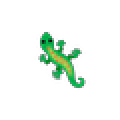

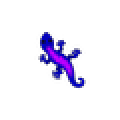

In [ ]:
#@title Pull the images from github according to genome { vertical-output: true }

target_img_1 = load_gecko('green')
target_img_2 = load_gecko('blue')

h, w = target_img_1.shape[:2]

p = (TARGET_PADDED_SIZE - h) // 2
padded_img_1 = tf.pad(target_img_1, [[p, p], [p,p], [0,0]])
padded_img_2 = tf.pad(target_img_2, [[p, p], [p,p], [0,0]])

print(padded_img_1.shape)

imshow(zoom(to_rgba(padded_img_1),2),fmt='png')
imshow(zoom(to_rgba(padded_img_2),2),fmt='png')



In [ ]:
#@title Initialize Training { vertical-output: true}


h, w = padded_img_1.shape[:2]
print(h,w)
seed = np.zeros([h, w, CHANNEL_N], np.float32)
seed[h//2, w//2, 3:]  = 1.0
# seed[h//2, w//2, -ENV_N:] = 0.0

def loss_f(x, y):
  return tf.reduce_mean(tf.square(to_rgba(x)-to_rgba(y)), [-2, -3, -1])

ca = CAModel()

loss_log = []

lr = 2e-3
lr_sched = tf.keras.optimizers.schedules.PiecewiseConstantDecay(
    [3000, 5000, 6000, 10000], [lr, lr*0.5, lr * 0.1, lr * 0.05, lr*0.01])
trainer = tf.keras.optimizers.Adam(lr_sched)


loss0 = loss_f(seed[None,...], padded_img_1[None,...]).numpy()

pool = SamplePool(x=np.repeat(seed[None, ...], POOL_SIZE, 0),
                  y=np.repeat(padded_img_1[None, ...], POOL_SIZE, 0),
                  z=np.repeat(0, POOL_SIZE,0))
if not loading_from_file:
    !mkdir -p {root_dir}/train_log && rm -f {root_dir}/train_log/*

60 60


In [ ]:
#@title Training Loop {vertical-output: true}

@tf.function
def train_step(x, y):
  iter_n = tf.random.uniform([], 64, 96, tf.int32)
  with tf.GradientTape() as g:
    for i in tf.range(iter_n):
      x = ca(x)
    loss = tf.reduce_mean(loss_f(x, y))
  grads = g.gradient(loss, ca.weights)
  grads = [g/(tf.norm(g)+1e-8) for g in grads]
  trainer.apply_gradients(zip(grads, ca.weights))
  return x, loss


@tf.function
def make_seed_env():
  h, w = (TARGET_PADDED_SIZE, TARGET_PADDED_SIZE)
  seed = np.zeros([h, w, CHANNEL_N], np.float32)
  seed[h//2, w//2, 3:] = 1.0
  seed[h//2,w//2,-ENV_N:] = 0
  return seed


@tf.function
def get_target(numSignals):
  if numSignals % 2 == 0:
    target_img_scale = target_img_1
  else:
    # target_img_scale = target_img_1
    target_img_scale = target_img_2

  img_w = target_img_scale.shape[:1][0]
  p = (TARGET_PADDED_SIZE - img_w) // 2
  pad_target_temp = tf.pad(to_rgba(target_img_scale), [[p, p], [p,p], [0,0]])
  return(pad_target_temp)


if fix_seed:
  tf.random.set_seed(1)

tic = datetime.datetime.now()
switch = 0
switch_step = 3
mirror = False

start_i = 6
end_i = 9
num_seeded = 3

if not loading_from_file:
    for i in range(10000+1):

      if i == BEHAVIOUR_SWITCH:
        # move signal to middling outputs rather than best outputs
        # (keep training best outputs to persist)
        start_i    = 6
        end_i      = 12
        num_seeded = 1


      if USE_PATTERN_POOL:
        batch = pool.sample(BATCH_SIZE)
        x0 = batch.x
        y0 = batch.y
        z0 = batch.z
        loss_rank = loss_f(x0, y0).numpy().argsort()[::-1]
        x0 = x0[loss_rank]
        y0 = y0[loss_rank]
        z0 = z0[loss_rank]

        x0[:num_seeded] = make_seed_env()
        y0[:num_seeded] = get_target(0)
        z0[:num_seeded] = np.zeros(num_seeded)
        if DAMAGE_N:
          # get location of signal input:
          stim_x, stim_y = get_stim(jitter=True)

          x0[start_i:end_i, stim_y, stim_x, -ENV_N:] = 1.0
          z0[start_i:end_i]     += 1   # keep track of how many signals this NCA has been given
          for z in range(start_i, end_i):
            y0[z,...] = get_target(z0[z])

      else:
        seed = make_seed_env()
        x0 = np.repeat(seed[None, ...], BATCH_SIZE, 0)

      x, loss = train_step(x0, y0)

      if USE_PATTERN_POOL:
        batch.x[:] = x
        batch.y[:] = y0
        batch.z[:] = z0
        batch.commit()

      step_i = len(loss_log)
      loss_log.append(loss.numpy())

      if step_i%10 == 0:
        generate_pool_figures(pool, step_i)
      if step_i%100 == 0:
        clear_output()
        visualize_batch(x0, x, y0, step_i)
        print(z0)
        plot_loss(loss_log)
        # export_model(ca, 'train_log/%04d'%step_i)
        export_model(ca, f'{root_dir}/train_log/{step_i:04d}.weights.h5')


      print('\r step: %d, log10(loss): %.3f'%(len(loss_log), np.log10(loss)), end='')
    toc = datetime.datetime.now()
    print("\n", toc - tic)
    loading_from_file = False

In [ ]:
#@title Generate data for Autoencoder

model_nums = [10000]
if loading_from_file:
  # only 10000 is stored in the external file
  # root_dir ='./jamess/NCA_AE/'
  !mkdir -p {root_dir}/train_log
  !cp {root_dir}/../3_bluegreen_substrate/train_log/* {root_dir}/train_log/
  # model_nums = [10000]
# else:
  # root_dir = ''

models = []
for i in model_nums:
  ca = CAModel()
  ca.load_weights(root_dir + '/train_log/%04d.weights.h5'%i)
  models.append(ca)

TIMESTEPS = 20000

# NCA state
x = np.zeros([len(models), TARGET_PADDED_SIZE, TARGET_PADDED_SIZE, CHANNEL_N], np.float32)
x[:,TARGET_PADDED_SIZE//2, TARGET_PADDED_SIZE//2, 3:] = 1.0
x[:,TARGET_PADDED_SIZE//2, TARGET_PADDED_SIZE//2, -ENV_N:] = 0.0


# record of all NCA states
xx = np.zeros([len(models), TARGET_PADDED_SIZE, TARGET_PADDED_SIZE, CHANNEL_N, TIMESTEPS], np.float32)
xx[...,0] = x

out_fn = root_dir + '/gecko_colourchange.mp4'



with VideoWriter(out_fn) as vid:
  for i in tqdm.trange(TIMESTEPS):

    if i > 0 and i % 150 == 0:
      stim_x,stim_y = get_stim(jitter=True);
      x[:,stim_y, stim_x,-ENV_N:] = 1.0

    vis = np.hstack(to_rgb(x))
    xx[...,i] = x


    vid.add(zoom(vis, 2))
    for ca, xk in zip(models, x):
      xk[:] = ca(xk[None,...])[0]


mvp.display_in_notebook(out_fn, maxduration=10000)


100%|██████████████████████████████████████████████████████████████████████████| 20000/20000 [01:30<00:00, 221.38it/s]


In [ ]:
xx.shape

(1, 60, 60, 17, 20000)

In [ ]:
if saving:
  np.save(f'{root_dir}/xx_bluegreen.npy', xx)
# xx = np.load(f'{root_dir}/xx_bluegreen.npy')
print(xx.shape)

(1, 60, 60, 17, 20000)


In [ ]:
xx = xx.transpose((4,0,1,2,3))
xx = xx.squeeze()
xx.shape

(20000, 60, 60, 17)

In [83]:
#@title Define autoencoder

from tensorflow.keras import layers
CHANNEL_N = 17

dims = (CHANNEL_N,) #(60,60,CHANNEL_N)


n_components = 3

enc_in = layers.InputLayer(input_shape=(dims))
enc_d1 = layers.Dense(units=64, activation='relu', name='enc_d1', kernel_regularizer=tf.keras.regularizers.L1L2(l1=1e-5, l2=1e-4))
enc_d2 = layers.Dense(units=n_components, activation='tanh', name='enc_d2',  kernel_regularizer=tf.keras.regularizers.L1L2(l1=1e-5, l2=1e-4))

dec_d1 = layers.Dense(units=64, activation='relu', name='dec_d2', kernel_regularizer=tf.keras.regularizers.L1L2(l1=1e-5, l2=1e-4))
dec_d0 = layers.Dense(units=CHANNEL_N, activation='relu', name='dec_d0', kernel_regularizer=tf.keras.regularizers.L1L2(l1=1e-5, l2=1e-4))


autoencoder = tf.keras.Sequential([enc_in,enc_d1,enc_d2,
                                   dec_d1,dec_d0])

autoencoder.compile(optimizer='adam', loss='mse')
autoencoder.summary()



/usr/local/lib/python3.11/dist-packages/keras/src/layers/core/input_layer.py:27: UserWarning: Argument `input_shape` is deprecated. Use `shape` instead.
  warnings.warn(


Model: "sequential_25"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ enc_d1 (Dense)                  │ (None, 64)             │         1,152 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ enc_d2 (Dense)                  │ (None, 3)              │           195 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dec_d2 (Dense)                  │ (None, 64)             │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dec_d0 (Dense)                  │ (None, 17)             │         1,105 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,708 (10.58 KB)

 Trainable params: 2,708 (10.58 KB)

 Non-trainable params: 0 (0.00 B)

In [71]:
#@title Need to split at substrate level, then divide into pixels {vertical-output:true}

from sklearn.model_selection import train_test_split
SAMPLES = 16000
VAL     = 2000


(xx_train, xx_test) = train_test_split(xx, test_size=VAL)
(xx_train, xx_val)  = train_test_split(xx_train, train_size=SAMPLES)


xx_train = xx_train.reshape((60*60*xx_train.shape[0], CHANNEL_N))
xx_val   = xx_val.reshape((60*60*xx_val.shape[0], CHANNEL_N))
xx_test  = xx_test.reshape((60*60*xx_test.shape[0], CHANNEL_N))

print(xx_train.shape)

(57600000, 17)


In [72]:
#@title Remove dead cells {vertical-output:true}

idx = xx_train[...,3:4] > 0.1
print(idx.shape)

xx_train_red = xx_train[idx.ravel(), :]
print(xx_train_red.shape)

idx = xx_test[...,3:4] > 0.1
xx_test_red = xx_test[idx.ravel(),:]
print(xx_test_red.shape)

idx = xx_val[...,3:4] > 0.1
xx_val_red = xx_val[idx.ravel(),:]
print(xx_val_red.shape)


(57600000, 1)
(4882069, 17)
(609522, 17)
(609845, 17)


In [73]:
#@title Load autoencoder model from disk

load_ae_from_file = False

if load_ae_from_file:
  autoencoder.load_weights(root_dir + 'autoencoder_model2.keras')


In [ ]:
#@title Train it {vertical-output:true}
if not load_ae_from_file:
  history = autoencoder.fit(
      xx_train_red, xx_train_red,
      epochs = 100,
      batch_size=1024,
      shuffle = True,
      validation_data=(xx_val_red,xx_val_red),
      # callbacks = [tf.keras.callbacks.EarlyStopping(patience=5)]
  )
  autoencoder.save(f"{root_dir}/autoencoder_model_tanh_long_train_3d_redl1.keras")


Epoch 1/100
4768/4768 ━━━━━━━━━━━━━━━━━━━━ 52s 10ms/step - loss: 0.0349 - val_loss: 0.0315
Epoch 2/100
4768/4768 ━━━━━━━━━━━━━━━━━━━━ 43s 9ms/step - loss: 0.0317 - val_loss: 0.0312
Epoch 3/100
4768/4768 ━━━━━━━━━━━━━━━━━━━━ 51s 11ms/step - loss: 0.0315 - val_loss: 0.0311
Epoch 4/100
4768/4768 ━━━━━━━━━━━━━━━━━━━━ 68s 14ms/step - loss: 0.0315 - val_loss: 0.0311
Epoch 5/100
4768/4768 ━━━━━━━━━━━━━━━━━━━━ 55s 11ms/step - loss: 0.0315 - val_loss: 0.0311
Epoch 6/100
4768/4768 ━━━━━━━━━━━━━━━━━━━━ 65s 14ms/step - loss: 0.0314 - val_loss: 0.0311
Epoch 7/100
4768/4768 ━━━━━━━━━━━━━━━━━━━━ 95s 20ms/step - loss: 0.0314 - val_loss: 0.0311
Epoch 8/100
4768/4768 ━━━━━━━━━━━━━━━━━━━━ 54s 11ms/step - loss: 0.0314 - val_loss: 0.0311
Epoch 9/100
4768/4768 ━━━━━━━━━━━━━━━━━━━━ 80s 17ms/step - loss: 0.0314 - val_loss: 0.0311
Epoch 10/100
4768/4768 ━━━━━━━━━━━━━━━━━━━━ 95s 20ms/step - loss: 0.0314 - val_loss: 0.0311
Epoch 11/100
4768/4768 ━━━━━━━━━━━━━━━━━━━━ 87s 18ms/step - loss: 0.0314 - val_loss: 0.031

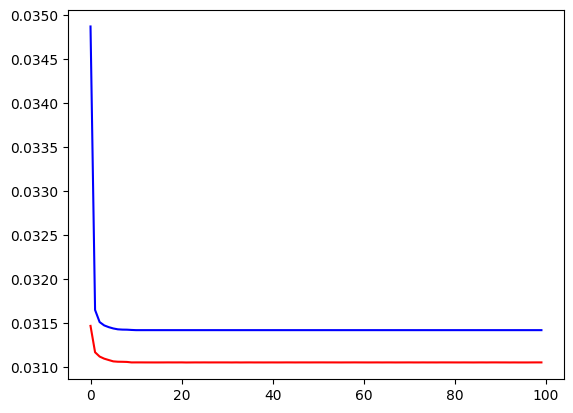

In [85]:
plt.plot(history.history['loss'], 'b-')
plt.plot(history.history['val_loss'], 'r-')
plt.show()

In [86]:
encoder = tf.keras.Sequential([enc_in,enc_d1,enc_d2])
encoder.summary()

decoder = tf.keras.Sequential([dec_d1,dec_d0])
decoder.summary()


Model: "sequential_26"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ enc_d1 (Dense)                  │ (None, 64)             │         1,152 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ enc_d2 (Dense)                  │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,347 (5.26 KB)

 Trainable params: 1,347 (5.26 KB)

 Non-trainable params: 0 (0.00 B)

Model: "sequential_27"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dec_d2 (Dense)                  │ (None, 64)             │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dec_d0 (Dense)                  │ (None, 17)             │         1,105 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,361 (5.32 KB)

 Trainable params: 1,361 (5.32 KB)

 Non-trainable params: 0 (0.00 B)

In [87]:
#@title Need to batch on inference for this much data {vertical-output:true}
full_embedding = np.zeros((xx_train_red.shape[0], 3), dtype=np.float32)
for b in range((xx_train_red.shape[0] // 1000)):
  batch = xx_train_red[b * 1000:(b+1)*1000]
  embedding = encoder(batch).numpy()
  full_embedding[b*1000:(b+1)*1000] = embedding
batch = xx_train_red[(b+1)*1000:]
embedding = encoder(batch).numpy()
full_embedding[(b+1)*1000:] = embedding
full_embedding.shape


(4882069, 3)

In [91]:
#@title Plot latent space {vertical-output: true}

SAMPLE_SIZE = 1_000_000

idx = np.random.choice(range(xx_train_red.shape[0]), SAMPLE_SIZE)

embed_idx = full_embedding[idx,:]
red_idx = embed_idx

xx_rgb = xx_train_red[idx,:3]

xx_rgb -= np.min(xx_rgb)
xx_rgb /= (np.max(xx_rgb))

colours  = xx_rgb



import matplotlib.pyplot as plt

fig = plt.figure(figsize=(20,20))

plt.scatter(red_idx[:,1],
            red_idx[:,2],
            c = colours,
            alpha = 0.2)

if saving:
  plt.savefig(f"{root_dir}/sample_latent_space_tanh_200_l12.png")
  plt.savefig(f"{root_dir}/sample_latent_space_tanh_200_l12.pdf")

plt.show()

Output hidden; open in https://colab.research.google.com to view.